<h1><font color="orange"><b>Interaction experiment on synthetic data</b></font></h1>

In [1]:
import pandas as pd

In [2]:
def inputdatatransf(xdata, funct):
  data = xdata.copy()
  X = list(data.columns)
  for i in range(len(X)):
    for j in range(i+1,len(X)):
      atr1 = X[i]
      atr2 = X[j]
      novy = f"{atr1} & {atr2}"
      data[novy] = [funct(x,y) for x,y in zip(data[atr1],data[atr2])]
  return data

In [3]:
def T(x,y):
  return x*y

In [4]:
def m(x,y):
  return min(x,y)

In [5]:
def M(x,y):
  return max(x,y)

In [6]:
def Ltnorm(x,y):
  return max(x+y-1,0)

In [7]:
def AP(x,y):
  return (x+y)/2

In [8]:
import numpy as np

First trial example

In [9]:
np.random.seed(42)

n = 2000

x1 = np.random.uniform(0,1,n)
x2 = np.random.uniform(0,1,n)

z = 0.5+x1-2*x2+1.5*x1*x2
p = 1/(1+np.exp(-z))

target = np.random.binomial(1,p,n)

In [10]:
df = pd.DataFrame({"x1":x1,"x2":x2,"y":target,"probability":p})
df

,x1,x2,y,probability
0,0.374540,0.261706,1,0.622026
1,0.950714,0.246979,0,0.787340
2,0.731994,0.906255,0,0.602177
3,0.598658,0.249546,1,0.695012
4,0.156019,0.271950,1,0.543828
...,...,...,...,...
1995,0.656955,0.442107,0,0.670049
1996,0.956615,0.334401,1,0.780341
1997,0.068958,0.394572,1,0.455277
1998,0.057055,0.529941,0,0.387585


In [11]:
target_col='y'
exp_col=['x1','x2']

X=df[exp_col]
y=df[target_col]

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, stratify=y, random_state=42)

In [13]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
trained_model=model.fit(X_train,y_train)

In [14]:
y_pred=model.predict(X_test)

In [15]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.67      0.39      0.49       272
           1       0.67      0.87      0.76       388

    accuracy                           0.67       660
   macro avg       0.67      0.63      0.62       660
weighted avg       0.67      0.67      0.65       660



In [16]:
dataclassic=X.copy()
datamultipl=inputdatatransf(X,T)
datamin=inputdatatransf(X,m)
datamax=inputdatatransf(X,M)
datalukasiewicz=inputdatatransf(X,Ltnorm)
dataarithmetic=inputdatatransf(X,AP)
datamultipl

,x1,x2,x1 & x2
0,0.374540,0.261706,0.098019
1,0.950714,0.246979,0.234806
2,0.731994,0.906255,0.663373
3,0.598658,0.249546,0.149393
4,0.156019,0.271950,0.042429
...,...,...,...
1995,0.656955,0.442107,0.290444
1996,0.956615,0.334401,0.319893
1997,0.068958,0.394572,0.027209
1998,0.057055,0.529941,0.030236


In [17]:
datasets=[('classic',dataclassic),('multiplication',datamultipl),('min',datamin),('max',datamax),('lukasiewicz',datalukasiewicz),('arithmetic mean',dataarithmetic)]

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=10, shuffle=True,random_state=42)

scoring = {"accuracy":"accuracy","f1":"f1","roc_auc":"roc_auc","log_loss":"neg_log_loss"}

In [19]:
results = []
coefficients = []

for name, data in datasets:
  model = LogisticRegression()
  scores = cross_validate(model,data,y,cv=cv,scoring=scoring,return_estimator=True)
  results.append({"Model":name,"Accuracy_mean":scores["test_accuracy"].mean(),"Accuracy_std":scores["test_accuracy"].std(),
                  "F1_mean":scores["test_f1"].mean(),"F1_std":scores["test_f1"].std(),"ROC_AUC_mean":scores["test_roc_auc"].mean(),
                  "ROC_AUC_std":scores["test_roc_auc"].std(),"LogLoss_mean":-scores["test_log_loss"].mean(),
                  "LogLoss_std":scores["test_log_loss"].std()})

  for fold, estimator in enumerate(scores["estimator"]):
        coefficients.append({"Model":name,"Fold":fold+1,"Intercept":estimator.intercept_[0],"Coefficients":estimator.coef_[0].copy()})

dataresult = pd.DataFrame(results)
coefresult = pd.DataFrame(coefficients)
dataresult

,Model,Accuracy_mean,Accuracy_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std,LogLoss_mean,LogLoss_std
0,classic,0.6590,0.020591,0.740420,0.018604,0.671536,0.041103,0.634087,0.020459
1,multiplication,0.6580,0.021932,0.742905,0.017795,0.672915,0.039767,0.630227,0.020533
2,min,0.6605,0.019551,0.744234,0.016884,0.670121,0.041364,0.631799,0.020825
3,max,0.6590,0.017578,0.743039,0.015073,0.670565,0.041549,0.631860,0.020801
4,lukasiewicz,0.6585,0.025402,0.740291,0.019947,0.674575,0.038623,0.630115,0.020480
5,arithmetic mean,0.6585,0.020500,0.739946,0.018486,0.671195,0.041144,0.634126,0.020463


In [20]:
coefresult

,Model,Fold,Intercept,Coefficients
0,classic,1,0.081103,"[1.7626655243649485, -1.1533162003189434]"
1,classic,2,0.156875,"[1.7737038534483818, -1.309378743409692]"
2,classic,3,0.173832,"[1.765442653176541, -1.3454385880967108]"
3,classic,4,0.084500,"[1.830406932931008, -1.2172360371475446]"
4,classic,5,0.243465,"[1.605832135031571, -1.3211422619684314]"
5,classic,6,0.148084,"[1.7089376781719905, -1.2328010737425559]"
6,classic,7,0.234148,"[1.730329176249782, -1.411993511500518]"
7,classic,8,0.193341,"[1.7285283572864403, -1.3284733551565377]"
8,classic,9,0.167977,"[1.7635867829686038, -1.3137855971379426]"
9,classic,10,0.175493,"[1.6219174208891802, -1.2043129807638893]"


In [21]:
sorted_result = dataresult.sort_values("F1_mean",ascending=False)
print(sorted_result[["Model","F1_mean","F1_std"]])

             Model   F1_mean    F1_std
2              min  0.744234  0.016884
3              max  0.743039  0.015073
1   multiplication  0.742905  0.017795
0          classic  0.740420  0.018604
4      lukasiewicz  0.740291  0.019947
5  arithmetic mean  0.739946  0.018486


In [22]:
sorted_result = dataresult.sort_values("ROC_AUC_mean",ascending=False)
print(sorted_result[["Model","ROC_AUC_mean","ROC_AUC_std"]])

             Model  ROC_AUC_mean  ROC_AUC_std
4      lukasiewicz      0.674575     0.038623
1   multiplication      0.672915     0.039767
0          classic      0.671536     0.041103
5  arithmetic mean      0.671195     0.041144
3              max      0.670565     0.041549
2              min      0.670121     0.041364


In [23]:
sorted_result = dataresult.sort_values("Accuracy_mean",ascending=False)
print(sorted_result[["Model","Accuracy_mean","Accuracy_std"]])

             Model  Accuracy_mean  Accuracy_std
2              min         0.6605      0.019551
0          classic         0.6590      0.020591
3              max         0.6590      0.017578
5  arithmetic mean         0.6585      0.020500
4      lukasiewicz         0.6585      0.025402
1   multiplication         0.6580      0.021932


In [24]:
sorted_result = dataresult.sort_values("LogLoss_mean")
print(sorted_result[["Model","LogLoss_mean","LogLoss_std"]])

             Model  LogLoss_mean  LogLoss_std
4      lukasiewicz      0.630115     0.020480
1   multiplication      0.630227     0.020533
2              min      0.631799     0.020825
3              max      0.631860     0.020801
0          classic      0.634087     0.020459
5  arithmetic mean      0.634126     0.020463


In [25]:
indices = np.arange(n)

train_idx, test_idx = train_test_split(indices,test_size=0.33,stratify=y,random_state=42)
predicted_probabilities = {}

for name, X_data in datasets:
    X_train = X_data.iloc[train_idx]
    X_test = X_data.iloc[test_idx]
    y_train = y[train_idx]

    model = LogisticRegression()

    model.fit(X_train,y_train)

    predicted_probabilities[name] = (model.predict_proba(X_test)[:, 1])

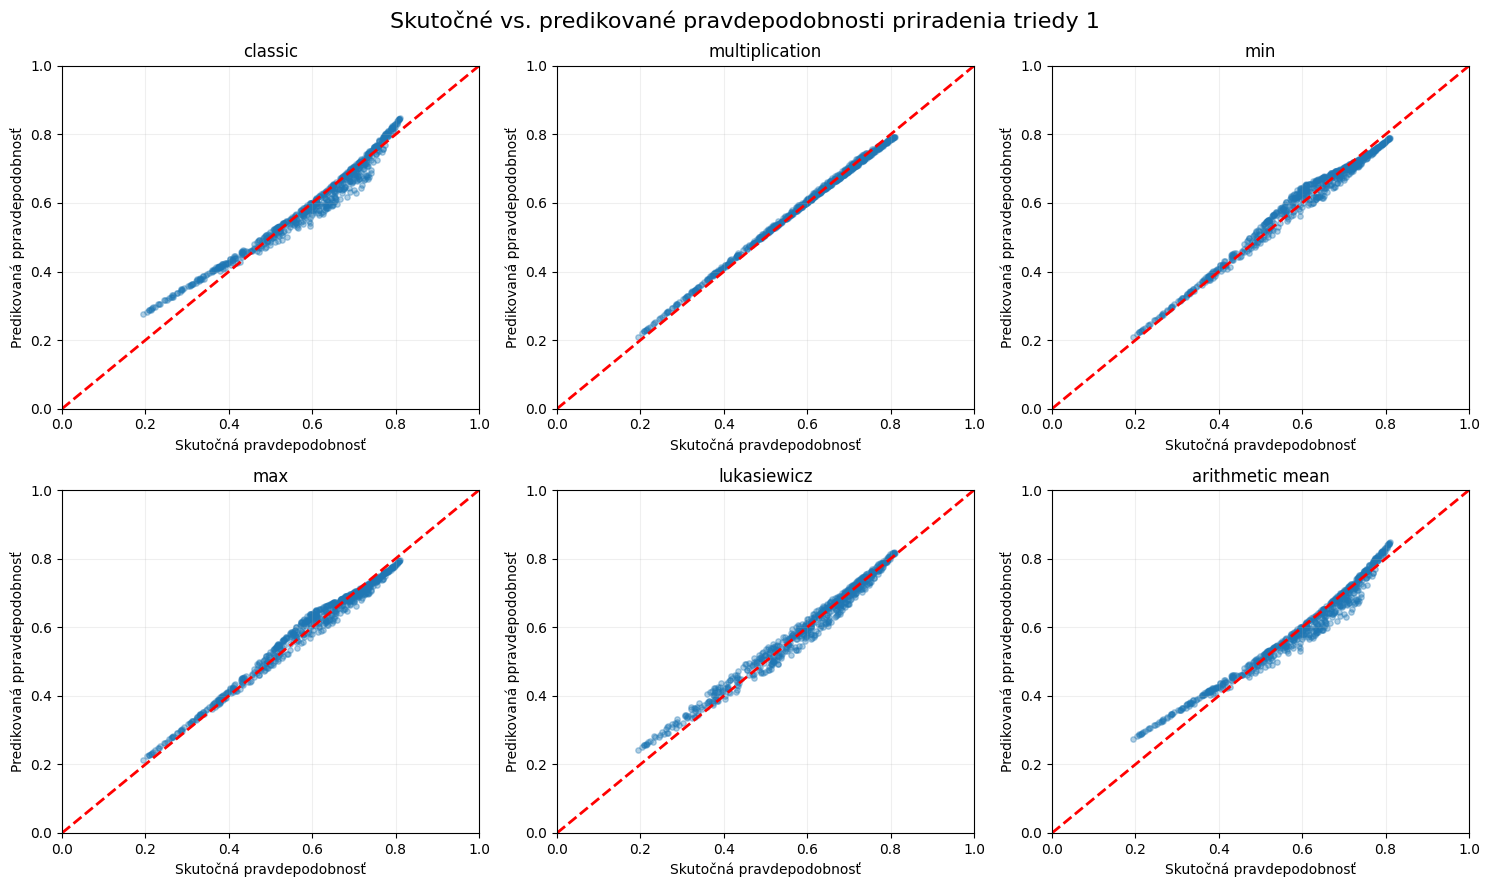

In [26]:
import matplotlib.pyplot as plt

true_p_test = p[test_idx]
fig, axes = plt.subplots(2, 3,figsize=(15, 9))
axes = axes.flatten()

for ax, (name, pred_p) in zip(axes,predicted_probabilities.items()):
    ax.scatter(true_p_test,pred_p,alpha=0.35,s=15)
    ax.plot([0, 1],[0, 1],"r--",linewidth=2)
    ax.set_title(name)
    ax.set_xlabel("Skutočná pravdepodobnosť")
    ax.set_ylabel("Predikovaná ppravdepodobnosť")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)

plt.suptitle("Skutočné vs. predikované pravdepodobnosti priradenia triedy 1",fontsize=16)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import mean_squared_error
errors=[]

for name, pred_p in predicted_probabilities.items():
  errors.append({"Model":name,"RMSE":np.sqrt(mean_squared_error(true_p_test,pred_p))})

dataerror=pd.DataFrame(errors)
dataerror

,Model,RMSE
0,classic,0.028313
1,multiplication,0.010160
2,min,0.019814
3,max,0.019261
4,lukasiewicz,0.020080
5,arithmetic mean,0.028245


In [28]:
sorted_error=dataerror.sort_values("RMSE")
print(sorted_error)

             Model      RMSE
1   multiplication  0.010160
3              max  0.019261
2              min  0.019814
4      lukasiewicz  0.020080
5  arithmetic mean  0.028245
0          classic  0.028313


In [29]:
rmse_cv=[]
predict_proba={}

for name, data in datasets:
  rmses=[]
  predictionsp=[]
  truep=[]

  for train_idx,test_idx in cv.split(data,y):
    X_train=data.iloc[train_idx]
    X_test=data.iloc[test_idx]
    y_train=y[train_idx]
    model=LogisticRegression()
    model.fit(X_train,y_train)
    pred_p=model.predict_proba(X_test)[:,1]
    true_p_test=p[test_idx]
    rmse=np.sqrt(mean_squared_error(true_p_test,pred_p))
    rmses.append(rmse)
    predictionsp.append(pred_p)
    truep.append(true_p_test)

  predict_proba[name]={"true_p":truep,"pred_p":predictionsp,"rmse":rmses}
  rmse_cv.append({"Model":name,"RMSE_mean":np.mean(rmses),"RMSE_std":np.std(rmses)})

In [30]:
resultdata=pd.DataFrame(results)
errordata=pd.DataFrame(rmse_cv)

resultdata=resultdata.merge(errordata,on="Model")
resultdata

,Model,Accuracy_mean,Accuracy_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std,LogLoss_mean,LogLoss_std,RMSE_mean,RMSE_std
0,classic,0.6590,0.020591,0.740420,0.018604,0.671536,0.041103,0.634087,0.020459,0.026798,0.001529
1,multiplication,0.6580,0.021932,0.742905,0.017795,0.672915,0.039767,0.630227,0.020533,0.007103,0.002903
2,min,0.6605,0.019551,0.744234,0.016884,0.670121,0.041364,0.631799,0.020825,0.017443,0.001404
3,max,0.6590,0.017578,0.743039,0.015073,0.670565,0.041549,0.631860,0.020801,0.017179,0.001584
4,lukasiewicz,0.6585,0.025402,0.740291,0.019947,0.674575,0.038623,0.630115,0.020480,0.020601,0.002532
5,arithmetic mean,0.6585,0.020500,0.739946,0.018486,0.671195,0.041144,0.634126,0.020463,0.026815,0.001553


In [31]:
sorted_result = resultdata.sort_values("RMSE_mean")
print(sorted_result[["Model","RMSE_mean","RMSE_std"]])

             Model  RMSE_mean  RMSE_std
1   multiplication   0.007103  0.002903
3              max   0.017179  0.001584
2              min   0.017443  0.001404
4      lukasiewicz   0.020601  0.002532
0          classic   0.026798  0.001529
5  arithmetic mean   0.026815  0.001553


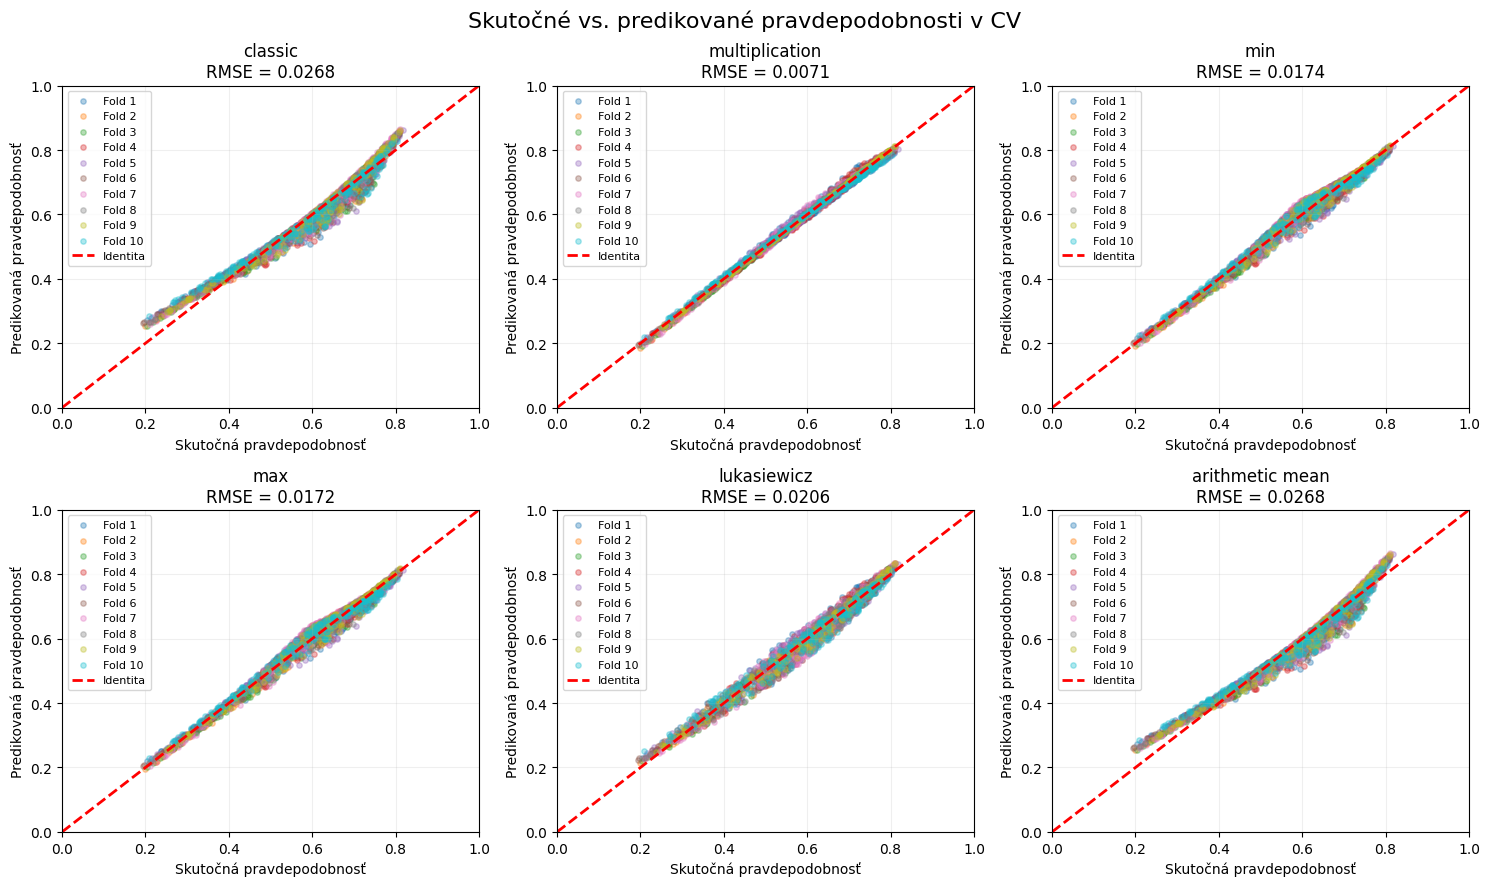

In [32]:
fig, axes = plt.subplots(2, 3,figsize=(15, 9))
axes = axes.flatten()
for ax, (name, results_cv) in zip(axes,predict_proba.items()):
    for fold, (true_p, pred_p) in enumerate(zip(results_cv["true_p"],results_cv["pred_p"])):
        ax.scatter(true_p,pred_p,alpha=0.35,s=15,label=f"Fold {fold+1}")
    ax.plot([0, 1],[0, 1],"r--",linewidth=2,label="Identita")
    rmse_mean = np.mean(results_cv["rmse"])
    ax.set_title(f"{name}\nRMSE = {rmse_mean:.4f}")
    ax.set_xlabel("Skutočná pravdepodobnosť")
    ax.set_ylabel("Predikovaná pravdepodobnosť")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.suptitle("Skutočné vs. predikované pravdepodobnosti v CV",fontsize=16)
plt.tight_layout()
plt.show()

Let's assume stronger interaction and bigger data.

In [33]:
np.random.seed(42)
n = 50000

x1 = np.random.uniform(0,1,n)
x2 = np.random.uniform(0,1,n)

z = 0.5+x1-2*x2+4*x1*x2
p = 1/(1+np.exp(-z))

target = np.random.binomial(1,p,n)

In [34]:
df = pd.DataFrame({"x1":x1,"x2":x2,"y":target,"probability":p})
df

,x1,x2,y,probability
0,0.374540,0.847237,1,0.610488
1,0.950714,0.494517,1,0.912317
2,0.731994,0.195466,1,0.804299
3,0.598658,0.736642,1,0.800490
4,0.156019,0.418678,1,0.519977
...,...,...,...,...
49995,0.622445,0.792305,1,0.819135
49996,0.226194,0.779253,0,0.468227
49997,0.748995,0.674453,1,0.872221
49998,0.521011,0.499447,1,0.743261


In [35]:
target_col='y'
exp_col=['x1','x2']

X=df[exp_col]
y=df[target_col]

In [36]:
dataclassic=X.copy()
datamultipl=inputdatatransf(X,T)
datamin=inputdatatransf(X,m)
datamax=inputdatatransf(X,M)
datalukasiewicz=inputdatatransf(X,Ltnorm)
dataarithmetic=inputdatatransf(X,AP)

In [37]:
datasets=[('classic',dataclassic),('multiplication',datamultipl),('min',datamin),('max',datamax),('lukasiewicz',datalukasiewicz),('arithmetic mean',dataarithmetic)]

In [38]:
results = []

for name, data in datasets:
  model = LogisticRegression()
  scores = cross_validate(model,data,y,cv=cv,scoring=scoring)
  results.append({"Model":name,"Accuracy_mean":scores["test_accuracy"].mean(),"Accuracy_std":scores["test_accuracy"].std(),
                  "F1_mean":scores["test_f1"].mean(),"F1_std":scores["test_f1"].std(),"ROC_AUC_mean":scores["test_roc_auc"].mean(),
                  "ROC_AUC_std":scores["test_roc_auc"].std(),"LogLoss_mean":-scores["test_log_loss"].mean(),
                  "LogLoss_std":scores["test_log_loss"].std()})

dataresult = pd.DataFrame(results)
dataresult

,Model,Accuracy_mean,Accuracy_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std,LogLoss_mean,LogLoss_std
0,classic,0.72264,0.005448,0.818958,0.003597,0.720531,0.008135,0.548248,0.005056
1,multiplication,0.72968,0.003675,0.825407,0.002259,0.729410,0.008096,0.540972,0.004973
2,min,0.72822,0.004977,0.822880,0.003327,0.727706,0.008339,0.542663,0.005086
3,max,0.72816,0.004997,0.822865,0.003357,0.727734,0.008297,0.542665,0.005059
4,lukasiewicz,0.72824,0.003621,0.824132,0.002141,0.726597,0.007201,0.543812,0.004583
5,arithmetic mean,0.72258,0.005388,0.818926,0.003573,0.720531,0.008138,0.548248,0.005058


In [39]:
sorted_result = dataresult.sort_values("LogLoss_mean")
print(sorted_result[["Model","LogLoss_mean","LogLoss_std"]])

             Model  LogLoss_mean  LogLoss_std
1   multiplication      0.540972     0.004973
2              min      0.542663     0.005086
3              max      0.542665     0.005059
4      lukasiewicz      0.543812     0.004583
0          classic      0.548248     0.005056
5  arithmetic mean      0.548248     0.005058


In [40]:
sorted_result = dataresult.sort_values("Accuracy_mean",ascending=False)
print(sorted_result[["Model","Accuracy_mean","Accuracy_std"]])

             Model  Accuracy_mean  Accuracy_std
1   multiplication        0.72968      0.003675
4      lukasiewicz        0.72824      0.003621
2              min        0.72822      0.004977
3              max        0.72816      0.004997
0          classic        0.72264      0.005448
5  arithmetic mean        0.72258      0.005388


In [41]:
sorted_result = dataresult.sort_values("F1_mean",ascending=False)
print(sorted_result[["Model","F1_mean","F1_std"]])

             Model   F1_mean    F1_std
1   multiplication  0.825407  0.002259
4      lukasiewicz  0.824132  0.002141
2              min  0.822880  0.003327
3              max  0.822865  0.003357
0          classic  0.818958  0.003597
5  arithmetic mean  0.818926  0.003573


In [42]:
sorted_result = dataresult.sort_values("ROC_AUC_mean",ascending=False)
print(sorted_result[["Model","ROC_AUC_mean","ROC_AUC_std"]])

             Model  ROC_AUC_mean  ROC_AUC_std
1   multiplication      0.729410     0.008096
3              max      0.727734     0.008297
2              min      0.727706     0.008339
4      lukasiewicz      0.726597     0.007201
5  arithmetic mean      0.720531     0.008138
0          classic      0.720531     0.008135


In [43]:
rmse_cv=[]
predict_proba={}

for name, data in datasets:
  rmses=[]
  predictionsp=[]
  truep=[]

  for train_idx,test_idx in cv.split(data,y):
    X_train=data.iloc[train_idx]
    X_test=data.iloc[test_idx]
    y_train=y[train_idx]
    model=LogisticRegression()
    model.fit(X_train,y_train)
    pred_p=model.predict_proba(X_test)[:,1]
    true_p_test=p[test_idx]
    rmse=np.sqrt(mean_squared_error(true_p_test,pred_p))
    rmses.append(rmse)
    predictionsp.append(pred_p)
    truep.append(true_p_test)

  predict_proba[name]={"true_p":truep,"pred_p":predictionsp,"rmse":rmses}
  rmse_cv.append({"Model":name,"RMSE_mean":np.mean(rmses),"RMSE_std":np.std(rmses)})

In [44]:
resultdata=pd.DataFrame(results)
errordata=pd.DataFrame(rmse_cv)

resultdata=resultdata.merge(errordata,on="Model")
resultdata

,Model,Accuracy_mean,Accuracy_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std,LogLoss_mean,LogLoss_std,RMSE_mean,RMSE_std
0,classic,0.72264,0.005448,0.818958,0.003597,0.720531,0.008135,0.548248,0.005056,0.052827,0.000588
1,multiplication,0.72968,0.003675,0.825407,0.002259,0.729410,0.008096,0.540972,0.004973,0.004664,0.000592
2,min,0.72822,0.004977,0.822880,0.003327,0.727706,0.008339,0.542663,0.005086,0.029103,0.000248
3,max,0.72816,0.004997,0.822865,0.003357,0.727734,0.008297,0.542665,0.005059,0.029056,0.000240
4,lukasiewicz,0.72824,0.003621,0.824132,0.002141,0.726597,0.007201,0.543812,0.004583,0.032508,0.000431
5,arithmetic mean,0.72258,0.005388,0.818926,0.003573,0.720531,0.008138,0.548248,0.005058,0.052836,0.000589


In [45]:
sorted_result = resultdata.sort_values("RMSE_mean")
print(sorted_result[["Model","RMSE_mean","RMSE_std"]])

             Model  RMSE_mean  RMSE_std
1   multiplication   0.004664  0.000592
3              max   0.029056  0.000240
2              min   0.029103  0.000248
4      lukasiewicz   0.032508  0.000431
0          classic   0.052827  0.000588
5  arithmetic mean   0.052836  0.000589


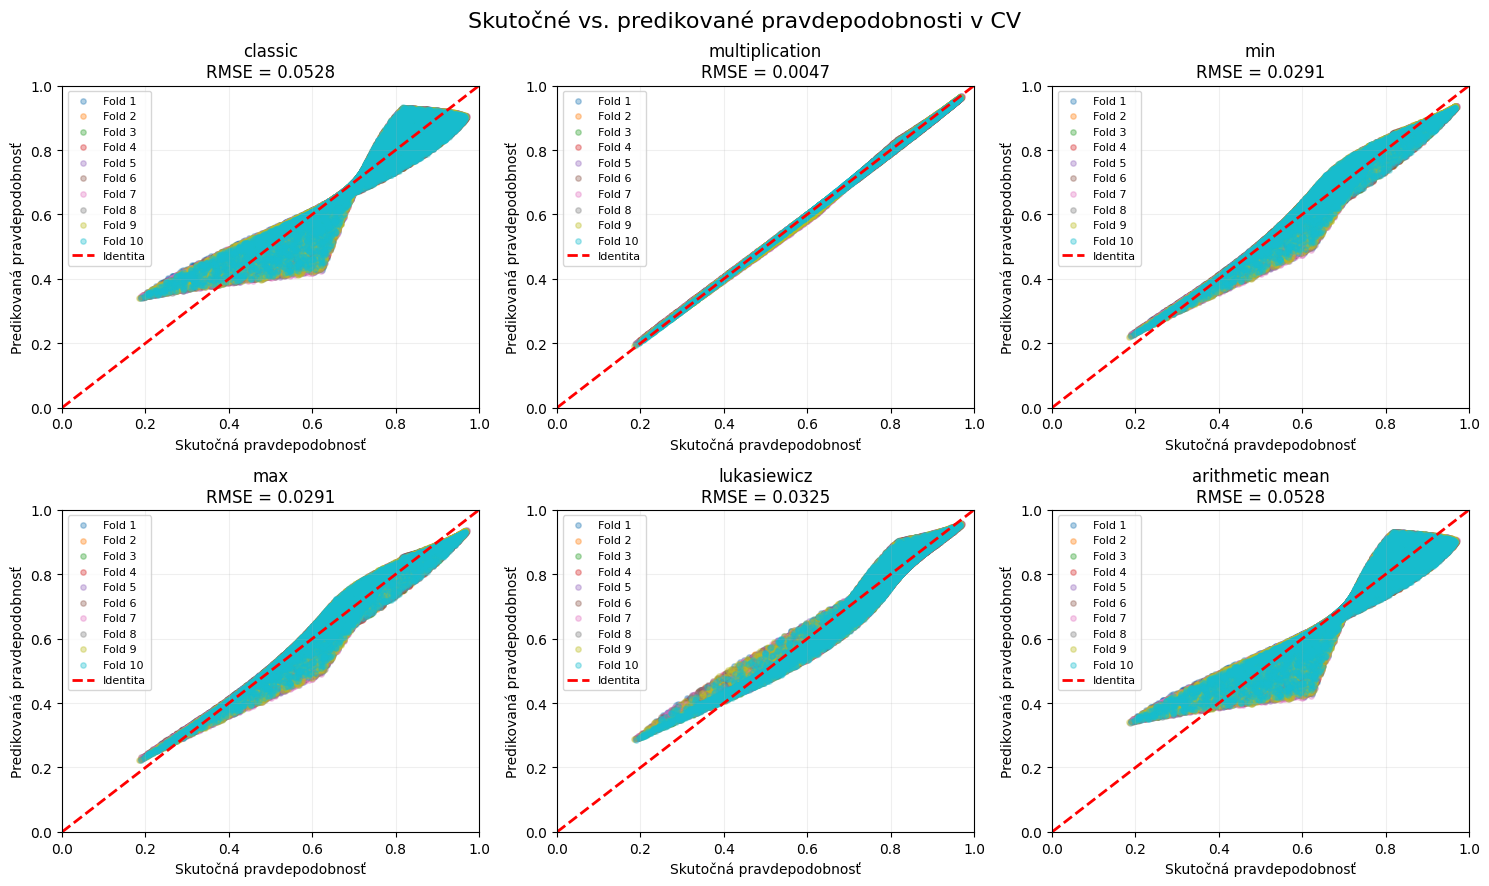

In [46]:
fig, axes = plt.subplots(2, 3,figsize=(15, 9))
axes = axes.flatten()
for ax, (name, results_cv) in zip(axes,predict_proba.items()):
    for fold, (true_p, pred_p) in enumerate(zip(results_cv["true_p"],results_cv["pred_p"])):
        ax.scatter(true_p,pred_p,alpha=0.35,s=15,label=f"Fold {fold+1}")
    ax.plot([0, 1],[0, 1],"r--",linewidth=2,label="Identita")
    rmse_mean = np.mean(results_cv["rmse"])
    ax.set_title(f"{name}\nRMSE = {rmse_mean:.4f}")
    ax.set_xlabel("Skutočná pravdepodobnosť")
    ax.set_ylabel("Predikovaná pravdepodobnosť")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.suptitle("Skutočné vs. predikované pravdepodobnosti v CV",fontsize=16)
plt.tight_layout()
plt.show()

A relationship between interaction coefficient and model error.

In [47]:
coefficients=np.arange(1,5.5,0.5)
coefficients

array([1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ])

In [48]:
n = 50000
final = []
rmse_results = []

np.random.seed(42)
x1 = np.random.uniform(0, 1, n)
x2 = np.random.uniform(0, 1, n)

for coeff in coefficients:
    z = 0.5 + x1 - 2*x2 + coeff*x1*x2
    p = 1 / (1 + np.exp(-z))
    target = np.random.binomial(1, p, n)

    df = pd.DataFrame({"x1":x1,"x2":x2,"y":target,"probability": p})
    X = df[["x1", "x2"]]
    y = df["y"]
    datasets = [("classic", X.copy()),("multiplication", inputdatatransf(X, T)),("min", inputdatatransf(X, m)),("max", inputdatatransf(X, M)),("lukasiewicz", inputdatatransf(X, Ltnorm)),("arithmetic mean", inputdatatransf(X, AP))]

    for name, data in datasets:
        model = LogisticRegression()
        scores = cross_validate(model, data, y, cv=cv, scoring=scoring)

        final.append({"Interaction":coeff,"Model":name,"Accuracy_mean":scores["test_accuracy"].mean(),"Accuracy_std":scores["test_accuracy"].std(),
            "F1_mean":scores["test_f1"].mean(),"F1_std":scores["test_f1"].std(),"ROC_AUC_mean":scores["test_roc_auc"].mean(),
            "ROC_AUC_std":scores["test_roc_auc"].std(),"LogLoss_mean":-scores["test_log_loss"].mean(),"LogLoss_std": scores["test_log_loss"].std()})

        rmses = []

        for train_idx, test_idx in cv.split(data, y):
            model = LogisticRegression()
            model.fit(data.iloc[train_idx], y.iloc[train_idx])

            pred_p = model.predict_proba(data.iloc[test_idx])[:, 1]
            true_p_test = p[test_idx]

            rmses.append(
                np.sqrt(mean_squared_error(true_p_test, pred_p))
            )

        rmse_results.append({"Interaction":coeff,"Model":name,"RMSE_mean":np.mean(rmses),"RMSE_std":np.std(rmses)})

resultdata = pd.DataFrame(final)
errordata = pd.DataFrame(rmse_results)

resultdata = resultdata.merge(errordata,on=["Interaction","Model"],validate="one_to_one")

In [49]:
resultdata

,Interaction,Model,Accuracy_mean,Accuracy_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std,LogLoss_mean,LogLoss_std,RMSE_mean,RMSE_std
0,1.0,classic,0.63066,0.003963,0.694146,0.004638,0.664044,0.004573,0.644942,0.002495,0.018049,0.000156
1,1.0,multiplication,0.63102,0.002736,0.698721,0.003544,0.664423,0.004642,0.644428,0.002405,0.003867,0.000476
2,1.0,min,0.63102,0.003201,0.699056,0.003722,0.664043,0.004562,0.644594,0.002413,0.010942,0.000166
3,1.0,max,0.63108,0.003146,0.699120,0.003657,0.664034,0.004556,0.644598,0.002408,0.010985,0.000188
4,1.0,lukasiewicz,0.63072,0.003020,0.696067,0.003839,0.664291,0.004704,0.644599,0.002490,0.009967,0.000240
5,1.0,arithmetic mean,0.63082,0.003934,0.694340,0.004603,0.664040,0.004565,0.644945,0.002491,0.018070,0.000177
6,1.5,classic,0.64752,0.004791,0.726985,0.004789,0.668477,0.006999,0.635184,0.003457,0.026141,0.000225
7,1.5,multiplication,0.64740,0.006867,0.730676,0.006243,0.669312,0.007956,0.633621,0.003816,0.002995,0.000612
8,1.5,min,0.64754,0.006308,0.730591,0.005810,0.668721,0.007145,0.633953,0.003374,0.015518,0.000232
9,1.5,max,0.64758,0.006287,0.730662,0.005810,0.668715,0.007144,0.633949,0.003374,0.015460,0.000218


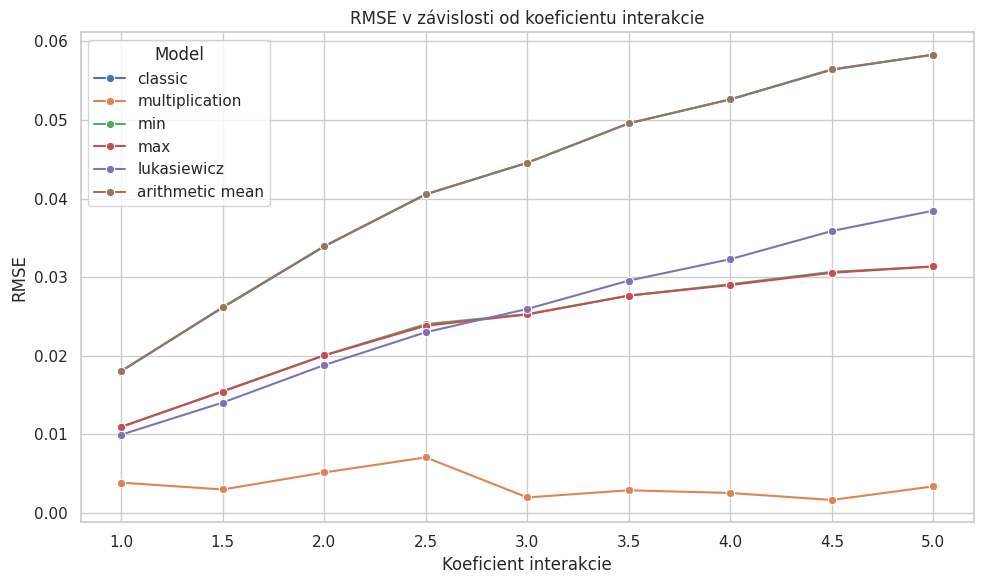

In [50]:
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.lineplot(data=resultdata,x="Interaction",y="RMSE_mean",hue="Model",marker="o")

plt.xlabel("Koeficient interakcie")
plt.ylabel("RMSE")
plt.title("RMSE v závislosti od koeficientu interakcie")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

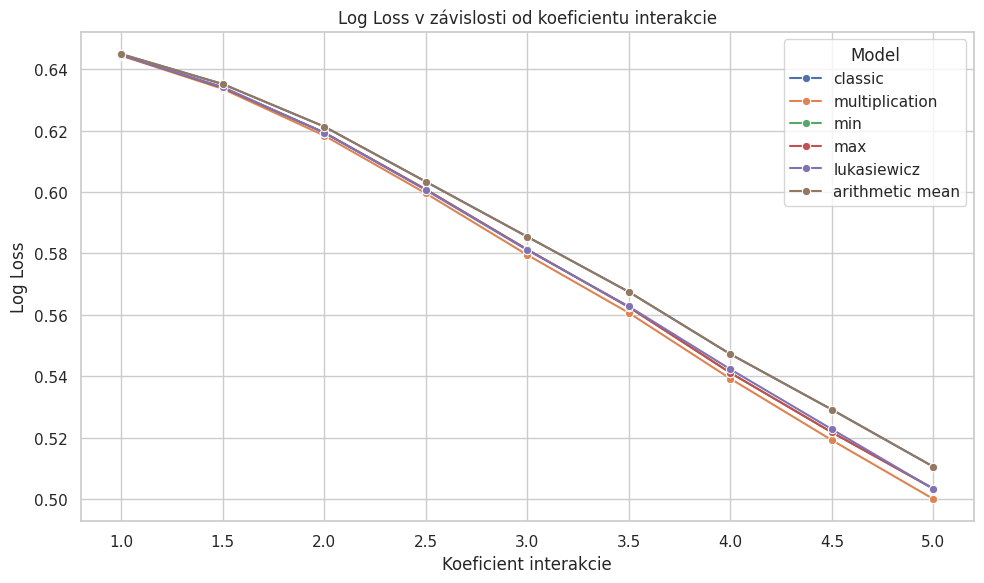

In [51]:
plt.figure(figsize=(10, 6))

sns.lineplot(data=resultdata,x="Interaction",y="LogLoss_mean",hue="Model",marker="o")

plt.xlabel("Koeficient interakcie")
plt.ylabel("Log Loss")
plt.title("Log Loss v závislosti od koeficientu interakcie")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

In [52]:
classic = (resultdata[resultdata["Model"]=="classic"][["Interaction","RMSE_mean","LogLoss_mean"]].rename(columns={"RMSE_mean":"Classic_RMSE","LogLoss_mean":"Classic_LogLoss"}))

comparison = resultdata.merge(classic,on="Interaction",validate="many_to_one")

comparison["RMSE_improvement_pct"] = (100*(comparison["Classic_RMSE"]-comparison["RMSE_mean"])/comparison["Classic_RMSE"])

comparison["LogLoss_improvement_pct"] = (100*(comparison["Classic_LogLoss"]-comparison["LogLoss_mean"])/comparison["Classic_LogLoss"])

In [53]:
comparison

,Interaction,Model,Accuracy_mean,Accuracy_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std,LogLoss_mean,LogLoss_std,RMSE_mean,RMSE_std,Classic_RMSE,Classic_LogLoss,RMSE_improvement_pct,LogLoss_improvement_pct
0,1.0,classic,0.63066,0.003963,0.694146,0.004638,0.664044,0.004573,0.644942,0.002495,0.018049,0.000156,0.018049,0.644942,0.000000,0.000000
1,1.0,multiplication,0.63102,0.002736,0.698721,0.003544,0.664423,0.004642,0.644428,0.002405,0.003867,0.000476,0.018049,0.644942,78.575740,0.079695
2,1.0,min,0.63102,0.003201,0.699056,0.003722,0.664043,0.004562,0.644594,0.002413,0.010942,0.000166,0.018049,0.644942,39.379810,0.054073
3,1.0,max,0.63108,0.003146,0.699120,0.003657,0.664034,0.004556,0.644598,0.002408,0.010985,0.000188,0.018049,0.644942,39.140648,0.053344
4,1.0,lukasiewicz,0.63072,0.003020,0.696067,0.003839,0.664291,0.004704,0.644599,0.002490,0.009967,0.000240,0.018049,0.644942,44.776657,0.053216
5,1.0,arithmetic mean,0.63082,0.003934,0.694340,0.004603,0.664040,0.004565,0.644945,0.002491,0.018070,0.000177,0.018049,0.644942,-0.112631,-0.000353
6,1.5,classic,0.64752,0.004791,0.726985,0.004789,0.668477,0.006999,0.635184,0.003457,0.026141,0.000225,0.026141,0.635184,0.000000,0.000000
7,1.5,multiplication,0.64740,0.006867,0.730676,0.006243,0.669312,0.007956,0.633621,0.003816,0.002995,0.000612,0.026141,0.635184,88.542053,0.246110
8,1.5,min,0.64754,0.006308,0.730591,0.005810,0.668721,0.007145,0.633953,0.003374,0.015518,0.000232,0.026141,0.635184,40.638132,0.193826
9,1.5,max,0.64758,0.006287,0.730662,0.005810,0.668715,0.007144,0.633949,0.003374,0.015460,0.000218,0.026141,0.635184,40.859126,0.194385


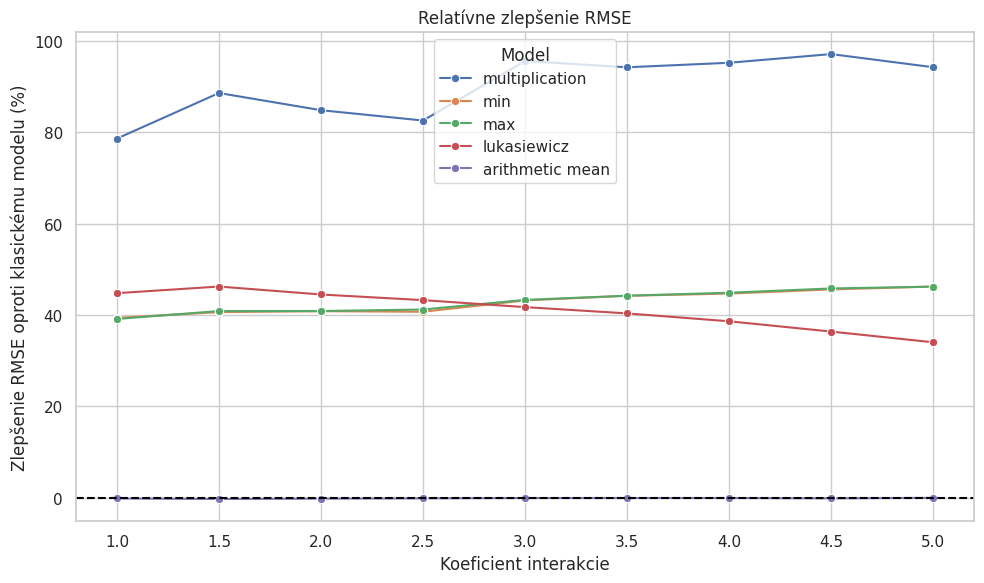

In [54]:
plt.figure(figsize=(10, 6))

sns.lineplot(data=comparison[comparison["Model"]!="classic"],x="Interaction",y="RMSE_improvement_pct",hue="Model",marker="o")

plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Koeficient interakcie")
plt.ylabel("Zlepšenie RMSE oproti klasickému modelu (%)")
plt.title("Relatívne zlepšenie RMSE")
plt.tight_layout()
plt.show()

Let's assume more interactions.

In [55]:
np.random.seed(42)
n = 50000

x1 = np.random.uniform(0,1,n)
x2 = np.random.uniform(0,1,n)
x3 = np.random.uniform(0,1,n)

z = 0.5+x1-2*x2+6*x3+4*x1*x2-3*x1*x3
p = 1/(1+np.exp(-z))

target = np.random.binomial(1,p,n)

In [56]:
df = pd.DataFrame({"x1":x1,"x2":x2,"x3":x3,"y":target,"probability":p})
df

,x1,x2,x3,y,probability
0,0.374540,0.847237,0.580779,1,0.963787
1,0.950714,0.494517,0.526972,1,0.982033
2,0.731994,0.195466,0.351037,1,0.939842
3,0.598658,0.736642,0.493213,1,0.969612
4,0.156019,0.418678,0.365097,1,0.890868
...,...,...,...,...,...
49995,0.622445,0.792305,0.229730,1,0.921282
49996,0.226194,0.779253,0.089677,0,0.586604
49997,0.748995,0.674453,0.196115,1,0.934426
49998,0.521011,0.499447,0.232094,1,0.890199


In [57]:
X=df[['x1','x2','x3']]
y=df['y']

In [58]:
datasets=[('classic',X.copy()),('multiplication',inputdatatransf(X,T)),('min',inputdatatransf(X,m)),('max',inputdatatransf(X,M)),('lukasiewicz',inputdatatransf(X,Ltnorm)),('arithmetic mean',inputdatatransf(X,AP))]

In [59]:
datasets[1]

('multiplication',
              x1        x2        x3   x1 & x2   x1 & x3   x2 & x3
 0      0.374540  0.847237  0.580779  0.317324  0.217525  0.492057
 1      0.950714  0.494517  0.526972  0.470144  0.500999  0.260596
 2      0.731994  0.195466  0.351037  0.143080  0.256957  0.068616
 3      0.598658  0.736642  0.493213  0.440997  0.295266  0.363321
 4      0.156019  0.418678  0.365097  0.065322  0.056962  0.152858
 ...         ...       ...       ...       ...       ...       ...
 49995  0.622445  0.792305  0.229730  0.493166  0.142994  0.182016
 49996  0.226194  0.779253  0.089677  0.176262  0.020284  0.069881
 49997  0.748995  0.674453  0.196115  0.505162  0.146889  0.132271
 49998  0.521011  0.499447  0.232094  0.260217  0.120923  0.115919
 49999  0.861707  0.389908  0.380496  0.335987  0.327876  0.148359
 
 [50000 rows x 6 columns])

In [60]:
results = []
coefficients = []

for name, data in datasets:
  model = LogisticRegression()
  scores = cross_validate(model,data,y,cv=cv,scoring=scoring,return_estimator=True)
  results.append({"Model":name,"Accuracy_mean":scores["test_accuracy"].mean(),"Accuracy_std":scores["test_accuracy"].std(),
                  "F1_mean":scores["test_f1"].mean(),"F1_std":scores["test_f1"].std(),"ROC_AUC_mean":scores["test_roc_auc"].mean(),
                  "ROC_AUC_std":scores["test_roc_auc"].std(),"LogLoss_mean":-scores["test_log_loss"].mean(),
                  "LogLoss_std":scores["test_log_loss"].std()})
  for fold, estimator in enumerate(scores["estimator"]):
        coefficients.append({"Model":name,"Fold":fold+1,"Intercept":estimator.intercept_[0],"Coefficients":estimator.coef_[0].copy()})

dataresult = pd.DataFrame(results)
coefresult = pd.DataFrame(coefficients)
dataresult

,Model,Accuracy_mean,Accuracy_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std,LogLoss_mean,LogLoss_std
0,classic,0.92094,0.000594,0.958750,0.000312,0.829308,0.013329,0.220574,0.005427
1,multiplication,0.92206,0.000943,0.959153,0.000475,0.837513,0.013226,0.216461,0.005334
2,min,0.92198,0.000944,0.959148,0.000483,0.835727,0.013387,0.217321,0.005438
3,max,0.92194,0.000988,0.959127,0.000502,0.835878,0.013418,0.217306,0.005470
4,lukasiewicz,0.92188,0.001114,0.959121,0.000572,0.835334,0.013277,0.217574,0.005498
5,arithmetic mean,0.92090,0.000595,0.958729,0.000313,0.829327,0.013324,0.220573,0.005439


In [61]:
coefficients

[{'Model': 'classic',
  'Fold': 1,
  'Intercept': np.float64(-0.0058883136890661),
  'Coefficients': array([ 2.31226433, -0.48427443,  4.75509368])},
 {'Model': 'classic',
  'Fold': 2,
  'Intercept': np.float64(-0.02027817263929709),
  'Coefficients': array([ 2.27354347, -0.4242382 ,  4.75228057])},
 {'Model': 'classic',
  'Fold': 3,
  'Intercept': np.float64(-0.03151796907062457),
  'Coefficients': array([ 2.31648476, -0.45635637,  4.78336353])},
 {'Model': 'classic',
  'Fold': 4,
  'Intercept': np.float64(-0.026074294871800446),
  'Coefficients': array([ 2.2985872 , -0.45232784,  4.79250212])},
 {'Model': 'classic',
  'Fold': 5,
  'Intercept': np.float64(0.013569892852402732),
  'Coefficients': array([ 2.2445555 , -0.43921205,  4.69794366])},
 {'Model': 'classic',
  'Fold': 6,
  'Intercept': np.float64(0.015401932067085015),
  'Coefficients': array([ 2.27367077, -0.46836535,  4.70176679])},
 {'Model': 'classic',
  'Fold': 7,
  'Intercept': np.float64(0.018069209575000862),
  'Coeffic

In [62]:
sorted_result = dataresult.sort_values("LogLoss_mean")
print(sorted_result[["Model","LogLoss_mean","LogLoss_std"]])

             Model  LogLoss_mean  LogLoss_std
1   multiplication      0.216461     0.005334
3              max      0.217306     0.005470
2              min      0.217321     0.005438
4      lukasiewicz      0.217574     0.005498
5  arithmetic mean      0.220573     0.005439
0          classic      0.220574     0.005427


In [63]:
sorted_result = dataresult.sort_values("Accuracy_mean",ascending=False)
print(sorted_result[["Model","Accuracy_mean","Accuracy_std"]])

             Model  Accuracy_mean  Accuracy_std
1   multiplication        0.92206      0.000943
2              min        0.92198      0.000944
3              max        0.92194      0.000988
4      lukasiewicz        0.92188      0.001114
0          classic        0.92094      0.000594
5  arithmetic mean        0.92090      0.000595


In [64]:
sorted_result = dataresult.sort_values("F1_mean",ascending=False)
print(sorted_result[["Model","F1_mean","F1_std"]])

             Model   F1_mean    F1_std
1   multiplication  0.959153  0.000475
2              min  0.959148  0.000483
3              max  0.959127  0.000502
4      lukasiewicz  0.959121  0.000572
0          classic  0.958750  0.000312
5  arithmetic mean  0.958729  0.000313


In [65]:
sorted_result = dataresult.sort_values("ROC_AUC_mean",ascending=False)
print(sorted_result[["Model","ROC_AUC_mean","ROC_AUC_std"]])

             Model  ROC_AUC_mean  ROC_AUC_std
1   multiplication      0.837513     0.013226
3              max      0.835878     0.013418
2              min      0.835727     0.013387
4      lukasiewicz      0.835334     0.013277
5  arithmetic mean      0.829327     0.013324
0          classic      0.829308     0.013329


In [66]:
rmse_cv=[]
predict_proba={}

for name, data in datasets:
  rmses=[]
  predictionsp=[]
  truep=[]

  for train_idx,test_idx in cv.split(data,y):
    X_train=data.iloc[train_idx]
    X_test=data.iloc[test_idx]
    y_train=y[train_idx]
    model=LogisticRegression()
    model.fit(X_train,y_train)
    pred_p=model.predict_proba(X_test)[:,1]
    true_p_test=p[test_idx]
    rmse=np.sqrt(mean_squared_error(true_p_test,pred_p))
    rmses.append(rmse)
    predictionsp.append(pred_p)
    truep.append(true_p_test)

  predict_proba[name]={"true_p":truep,"pred_p":predictionsp,"rmse":rmses}
  rmse_cv.append({"Model":name,"RMSE_mean":np.mean(rmses),"RMSE_std":np.std(rmses)})

In [67]:
resultdata=pd.DataFrame(results)
errordata=pd.DataFrame(rmse_cv)

resultdata=resultdata.merge(errordata,on="Model")
resultdata

,Model,Accuracy_mean,Accuracy_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std,LogLoss_mean,LogLoss_std,RMSE_mean,RMSE_std
0,classic,0.92094,0.000594,0.958750,0.000312,0.829308,0.013329,0.220574,0.005427,0.027008,0.000747
1,multiplication,0.92206,0.000943,0.959153,0.000475,0.837513,0.013226,0.216461,0.005334,0.002976,0.000480
2,min,0.92198,0.000944,0.959148,0.000483,0.835727,0.013387,0.217321,0.005438,0.013957,0.000287
3,max,0.92194,0.000988,0.959127,0.000502,0.835878,0.013418,0.217306,0.005470,0.014276,0.000307
4,lukasiewicz,0.92188,0.001114,0.959121,0.000572,0.835334,0.013277,0.217574,0.005498,0.015904,0.000357
5,arithmetic mean,0.92090,0.000595,0.958729,0.000313,0.829327,0.013324,0.220573,0.005439,0.027012,0.000749


In [68]:
sorted_result = resultdata.sort_values("RMSE_mean")
print(sorted_result[["Model","RMSE_mean","RMSE_std"]])

             Model  RMSE_mean  RMSE_std
1   multiplication   0.002976  0.000480
2              min   0.013957  0.000287
3              max   0.014276  0.000307
4      lukasiewicz   0.015904  0.000357
0          classic   0.027008  0.000747
5  arithmetic mean   0.027012  0.000749


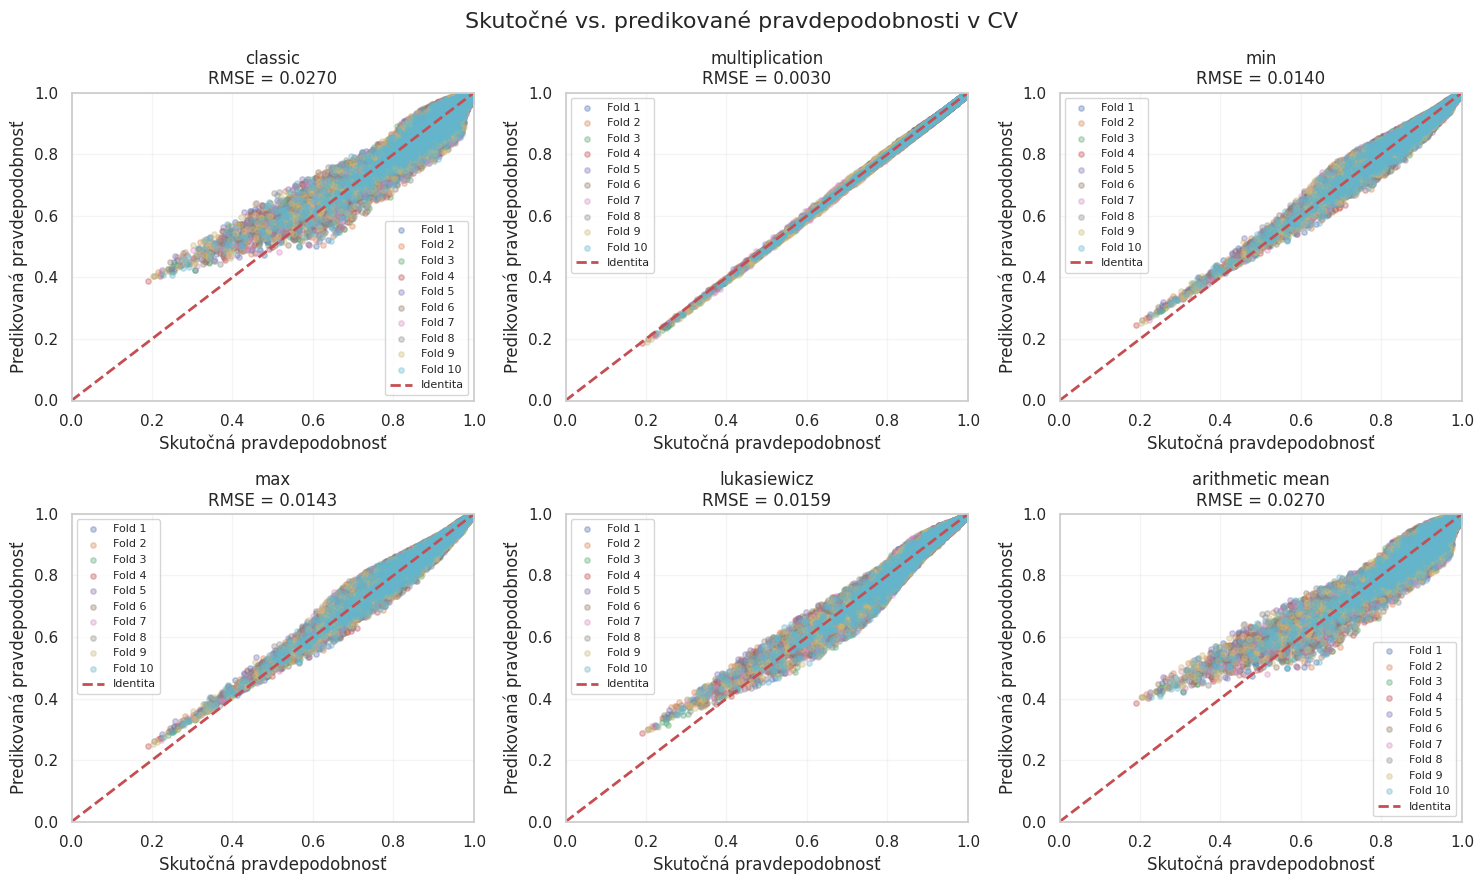

In [69]:
fig, axes = plt.subplots(2, 3,figsize=(15, 9))
axes = axes.flatten()
for ax, (name, results_cv) in zip(axes,predict_proba.items()):
    for fold, (true_p, pred_p) in enumerate(zip(results_cv["true_p"],results_cv["pred_p"])):
        ax.scatter(true_p,pred_p,alpha=0.35,s=15,label=f"Fold {fold+1}")
    ax.plot([0, 1],[0, 1],"r--",linewidth=2,label="Identita")
    rmse_mean = np.mean(results_cv["rmse"])
    ax.set_title(f"{name}\nRMSE = {rmse_mean:.4f}")
    ax.set_xlabel("Skutočná pravdepodobnosť")
    ax.set_ylabel("Predikovaná pravdepodobnosť")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.suptitle("Skutočné vs. predikované pravdepodobnosti v CV",fontsize=16)
plt.tight_layout()
plt.show()

Let's assume different kind of interaction.

In [70]:
np.random.seed(42)
n = 50000

x1 = np.random.uniform(0,1,n)
x2 = np.random.uniform(0,1,n)
x3 = np.random.uniform(0,1,n)

z = 0.5+x1-2*x2+6*np.minimum(x2,x3)
p = 1/(1+np.exp(-z))

target = np.random.binomial(1,p,n)

In [71]:
df = pd.DataFrame({"x1":x1,"x2":x2,"x3":x3,"y":target,"probability":p})
df

,x1,x2,x3,y,probability
0,0.374540,0.847237,0.580779,1,0.934914
1,0.950714,0.494517,0.526972,1,0.968592
2,0.731994,0.195466,0.351037,1,0.882244
3,0.598658,0.736642,0.493213,1,0.929867
4,0.156019,0.418678,0.365097,1,0.881764
...,...,...,...,...,...
49995,0.622445,0.792305,0.229730,1,0.714271
49996,0.226194,0.779253,0.089677,1,0.426963
49997,0.748995,0.674453,0.196115,1,0.745884
49998,0.521011,0.499447,0.232094,1,0.804503


In [72]:
X=df[['x1','x2','x3']]
y=df['y']

In [73]:
datasets=[('classic',X.copy()),('multiplication',inputdatatransf(X,T)),('min',inputdatatransf(X,m)),('max',inputdatatransf(X,M)),('lukasiewicz',inputdatatransf(X,Ltnorm)),('arithmetic mean',inputdatatransf(X,AP))]

In [74]:
results = []

for name, data in datasets:
  model = LogisticRegression()
  scores = cross_validate(model,data,y,cv=cv,scoring=scoring)
  results.append({"Model":name,"Accuracy_mean":scores["test_accuracy"].mean(),"Accuracy_std":scores["test_accuracy"].std(),
                  "F1_mean":scores["test_f1"].mean(),"F1_std":scores["test_f1"].std(),"ROC_AUC_mean":scores["test_roc_auc"].mean(),
                  "ROC_AUC_std":scores["test_roc_auc"].std(),"LogLoss_mean":-scores["test_log_loss"].mean(),
                  "LogLoss_std":scores["test_log_loss"].std()})

dataresult = pd.DataFrame(results)
dataresult

,Model,Accuracy_mean,Accuracy_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std,LogLoss_mean,LogLoss_std
0,classic,0.82852,0.000588,0.906141,0.000312,0.720158,0.011012,0.413871,0.004634
1,multiplication,0.83662,0.002386,0.908838,0.001421,0.763618,0.011815,0.391173,0.006271
2,min,0.83678,0.003533,0.908446,0.002072,0.775445,0.011273,0.385059,0.006466
3,max,0.83700,0.003628,0.908610,0.002119,0.775449,0.011309,0.385066,0.006408
4,lukasiewicz,0.83078,0.000827,0.907104,0.000489,0.734646,0.009689,0.405661,0.004595
5,arithmetic mean,0.82850,0.000581,0.906125,0.000313,0.720158,0.011010,0.413870,0.004639


In [75]:
sorted_result = dataresult.sort_values("LogLoss_mean")
print(sorted_result[["Model","LogLoss_mean","LogLoss_std"]])

             Model  LogLoss_mean  LogLoss_std
2              min      0.385059     0.006466
3              max      0.385066     0.006408
1   multiplication      0.391173     0.006271
4      lukasiewicz      0.405661     0.004595
5  arithmetic mean      0.413870     0.004639
0          classic      0.413871     0.004634


In [76]:
sorted_result = dataresult.sort_values("Accuracy_mean",ascending=False)
print(sorted_result[["Model","Accuracy_mean","Accuracy_std"]])

             Model  Accuracy_mean  Accuracy_std
3              max        0.83700      0.003628
2              min        0.83678      0.003533
1   multiplication        0.83662      0.002386
4      lukasiewicz        0.83078      0.000827
0          classic        0.82852      0.000588
5  arithmetic mean        0.82850      0.000581


In [77]:
sorted_result = dataresult.sort_values("F1_mean",ascending=False)
print(sorted_result[["Model","F1_mean","F1_std"]])

             Model   F1_mean    F1_std
1   multiplication  0.908838  0.001421
3              max  0.908610  0.002119
2              min  0.908446  0.002072
4      lukasiewicz  0.907104  0.000489
0          classic  0.906141  0.000312
5  arithmetic mean  0.906125  0.000313


In [78]:
sorted_result = dataresult.sort_values("ROC_AUC_mean",ascending=False)
print(sorted_result[["Model","ROC_AUC_mean","ROC_AUC_std"]])

             Model  ROC_AUC_mean  ROC_AUC_std
3              max      0.775449     0.011309
2              min      0.775445     0.011273
1   multiplication      0.763618     0.011815
4      lukasiewicz      0.734646     0.009689
0          classic      0.720158     0.011012
5  arithmetic mean      0.720158     0.011010


In [79]:
rmse_cv=[]
predict_proba={}

for name, data in datasets:
  rmses=[]
  predictionsp=[]
  truep=[]

  for train_idx,test_idx in cv.split(data,y):
    X_train=data.iloc[train_idx]
    X_test=data.iloc[test_idx]
    y_train=y[train_idx]
    model=LogisticRegression()
    model.fit(X_train,y_train)
    pred_p=model.predict_proba(X_test)[:,1]
    true_p_test=p[test_idx]
    rmse=np.sqrt(mean_squared_error(true_p_test,pred_p))
    rmses.append(rmse)
    predictionsp.append(pred_p)
    truep.append(true_p_test)

  predict_proba[name]={"true_p":truep,"pred_p":predictionsp,"rmse":rmses}
  rmse_cv.append({"Model":name,"RMSE_mean":np.mean(rmses),"RMSE_std":np.std(rmses)})

In [80]:
resultdata=pd.DataFrame(results)
errordata=pd.DataFrame(rmse_cv)

resultdata=resultdata.merge(errordata,on="Model")
resultdata

,Model,Accuracy_mean,Accuracy_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std,LogLoss_mean,LogLoss_std,RMSE_mean,RMSE_std
0,classic,0.82852,0.000588,0.906141,0.000312,0.720158,0.011012,0.413871,0.004634,0.088265,0.000820
1,multiplication,0.83662,0.002386,0.908838,0.001421,0.763618,0.011815,0.391173,0.006271,0.038378,0.000535
2,min,0.83678,0.003533,0.908446,0.002072,0.775445,0.011273,0.385059,0.006466,0.004782,0.000417
3,max,0.83700,0.003628,0.908610,0.002119,0.775449,0.011309,0.385066,0.006408,0.004530,0.000419
4,lukasiewicz,0.83078,0.000827,0.907104,0.000489,0.734646,0.009689,0.405661,0.004595,0.077473,0.000658
5,arithmetic mean,0.82850,0.000581,0.906125,0.000313,0.720158,0.011010,0.413870,0.004639,0.088259,0.000818


In [81]:
sorted_result = resultdata.sort_values("RMSE_mean")
print(sorted_result[["Model","RMSE_mean","RMSE_std"]])

             Model  RMSE_mean  RMSE_std
3              max   0.004530  0.000419
2              min   0.004782  0.000417
1   multiplication   0.038378  0.000535
4      lukasiewicz   0.077473  0.000658
5  arithmetic mean   0.088259  0.000818
0          classic   0.088265  0.000820


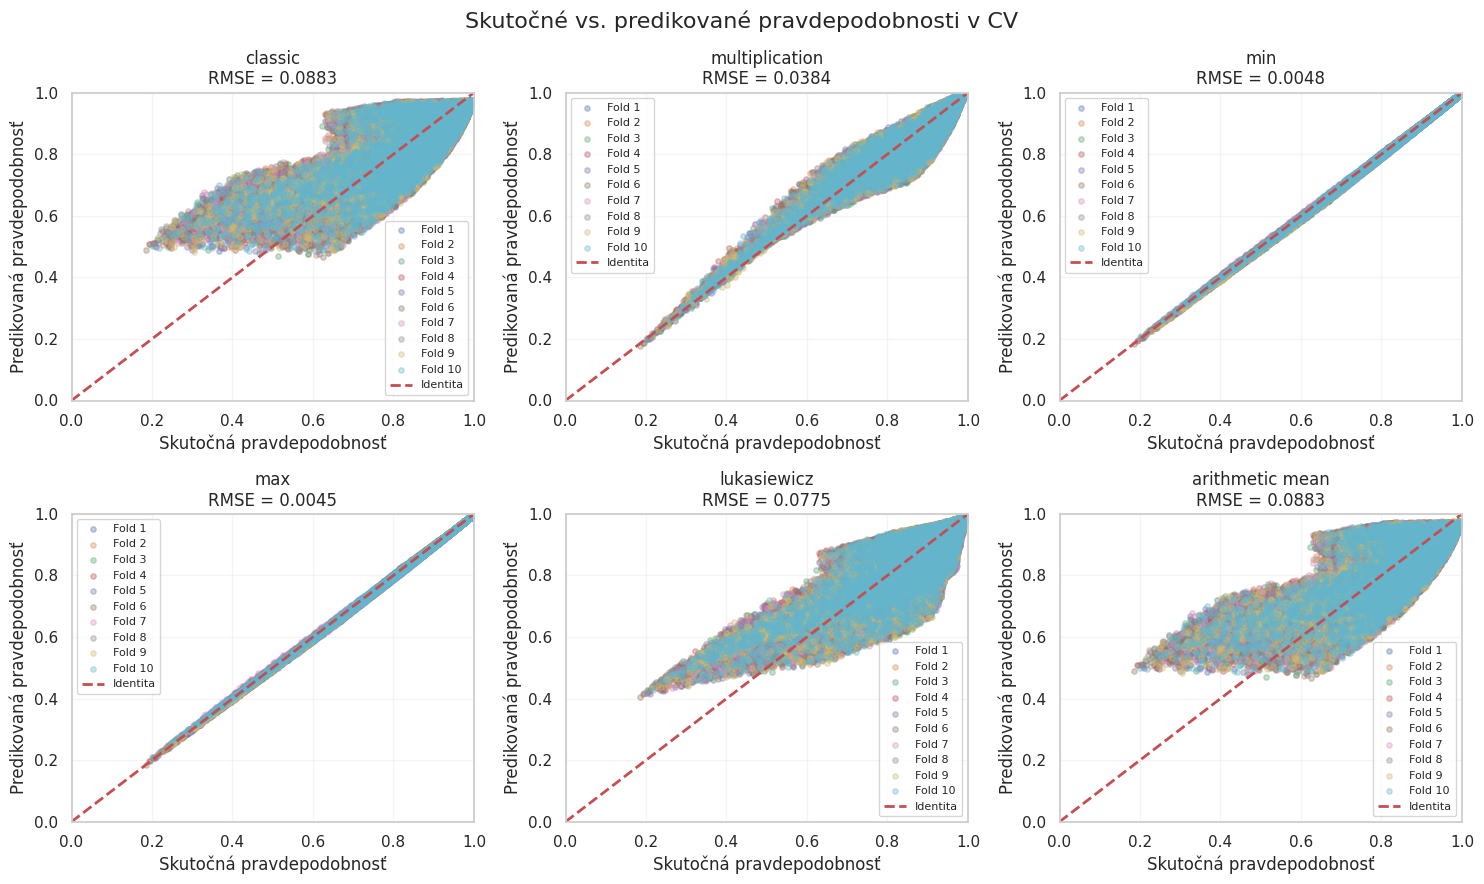

In [82]:
fig, axes = plt.subplots(2, 3,figsize=(15, 9))
axes = axes.flatten()
for ax, (name, results_cv) in zip(axes,predict_proba.items()):
    for fold, (true_p, pred_p) in enumerate(zip(results_cv["true_p"],results_cv["pred_p"])):
        ax.scatter(true_p,pred_p,alpha=0.35,s=15,label=f"Fold {fold+1}")
    ax.plot([0, 1],[0, 1],"r--",linewidth=2,label="Identita")
    rmse_mean = np.mean(results_cv["rmse"])
    ax.set_title(f"{name}\nRMSE = {rmse_mean:.4f}")
    ax.set_xlabel("Skutočná pravdepodobnosť")
    ax.set_ylabel("Predikovaná pravdepodobnosť")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.suptitle("Skutočné vs. predikované pravdepodobnosti v CV",fontsize=16)
plt.tight_layout()
plt.show()